# Task 3: Resume / Candidate Screening System
**Future Interns - Machine Learning Track**

**Goal:** automatically screen and rank resumes for a given job role, and show which skills each candidate is missing.

**Workflow:** load resumes -> clean text -> extract skills -> match against job description -> score & rank -> skill gap report.

**Score formula:** `0.60 x skill match + 0.25 x text similarity (TF-IDF cosine) + 0.15 x experience fit`

In [1]:
import os, re, glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import warnings
warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 80)

## 1. Load resumes and job description

In [2]:
resumes = []
for path in sorted(glob.glob("data/resumes/*.txt")):
    with open(path, encoding="utf-8") as f:
        text = f.read()
    resumes.append({"file": os.path.basename(path), "name": text.split("\n")[0].strip(), "raw": text})
df = pd.DataFrame(resumes)

with open("data/job_description.txt", encoding="utf-8") as f:
    jd_text = f.read()

print(len(df), "resumes loaded")
print(jd_text)

40 resumes loaded
Job Title: Machine Learning Engineer

About the role
We are looking for a Machine Learning Engineer to build and deploy models that solve real business problems.

Required Skills:
Python, machine learning, scikit-learn, pandas, numpy, SQL, git, deep learning

Nice to have:
TensorFlow, PyTorch, Docker, AWS, NLP

Experience: 2+ years preferred



## 2. Text cleaning

In [3]:
def clean_text(t):
    t = t.lower()
    t = re.sub(r"[^a-z0-9+#./\s-]", " ", t)
    return re.sub(r"\s+", " ", t).strip()

df["clean"] = df["raw"].apply(clean_text)
jd_clean = clean_text(jd_text)

## 3. Skill extraction
A skills dictionary is matched with word-boundary rules so that `java` does not match `javascript` and `c++`/`node.js` are handled correctly.

In [4]:
SKILLS_DB = [
    "python", "java", "c++", "sql", "excel", "git", "linux", "docker", "kubernetes", "aws", "terraform", "ci/cd",
    "machine learning", "deep learning", "nlp", "statistics", "data visualization", "scikit-learn", "pandas", "numpy",
    "matplotlib", "tensorflow", "pytorch", "power bi", "tableau",
    "html", "css", "javascript", "react", "node.js", "mongodb", "rest api",
]

def extract_skills(text):
    text = clean_text(text)
    found = set()
    for s in SKILLS_DB:
        if re.search(r"(?<![\w+#])" + re.escape(s) + r"(?![\w+#])", text):
            found.add(s)
    return found

df["skills"] = df["raw"].apply(extract_skills)
df[["name", "skills"]].head()

,name,skills
0,Isha Mukherjee,"{git, docker, terraform, ci/cd, kubernetes, python, linux, aws}"
1,Soham Sharma,"{git, docker, terraform, ci/cd, python, aws, linux}"
2,Rohan Singh,"{tableau, pandas, statistics, data visualization, power bi, excel, python, sql}"
3,Riya Nair,"{git, pandas, pytorch, tensorflow, numpy, machine learning, docker, python, ..."
4,Meera Das,"{pandas, statistics, data visualization, power bi, excel, sql}"


## 4. Parse the job description
Skills under *Required* and *Nice to have* are separated, and a minimum experience level is read from the text.

In [5]:
def parse_jd(text):
    low = text.lower()
    req_part = low.split("required skills")[1].split("nice to have")[0] if "required skills" in low else low
    nice_part = low.split("nice to have")[1] if "nice to have" in low else ""
    m = re.search(r"(\d+)\+?\s*years", nice_part.split("experience")[-1] if "experience" in nice_part else low)
    years = int(m.group(1)) if m else 0
    return extract_skills(req_part), extract_skills(nice_part.split("experience")[0]), years

required, preferred, min_years = parse_jd(jd_text)
print("required :", sorted(required))
print("preferred:", sorted(preferred))
print("min years:", min_years)

required : ['deep learning', 'git', 'machine learning', 'numpy', 'pandas', 'python', 'scikit-learn', 'sql']
preferred: ['aws', 'docker', 'nlp', 'pytorch', 'tensorflow']
min years: 2


## 5. Experience extraction

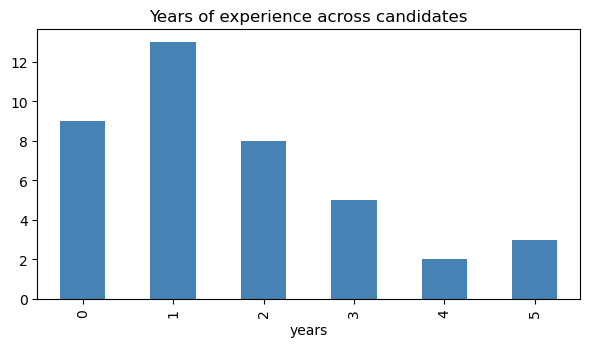

In [6]:
def get_years(text):
    m = re.search(r"(\d+)\+?\s*years", text.lower())
    return int(m.group(1)) if m else 0

df["years"] = df["raw"].apply(get_years)
df["years"].value_counts().sort_index().plot(kind="bar", color="steelblue", figsize=(7, 3.5))
plt.title("Years of experience across candidates")
plt.show()

## 6. Scoring & ranking

In [7]:
def rank_candidates(df, jd_text):
    required, preferred, min_years = parse_jd(jd_text)
    vec = TfidfVectorizer(ngram_range=(1, 2), stop_words="english")
    mat = vec.fit_transform(list(df["clean"]) + [clean_text(jd_text)])
    sim = cosine_similarity(mat[:-1], mat[-1]).ravel()

    rows = []
    for i, r in df.reset_index(drop=True).iterrows():
        req_hit = r["skills"] & required
        pref_hit = r["skills"] & preferred
        req_score = len(req_hit) / len(required) if required else 0
        pref_score = len(pref_hit) / len(preferred) if preferred else 0
        skill_score = 0.75 * req_score + 0.25 * pref_score
        exp_score = min(r["years"] / min_years, 1.0) if min_years else 1.0
        final = 0.60 * skill_score + 0.25 * sim[i] + 0.15 * exp_score
        rows.append({
            "name": r["name"], "file": r["file"], "years": r["years"],
            "required_match_%": round(req_score * 100), "preferred_match_%": round(pref_score * 100),
            "text_similarity": round(sim[i], 3), "final_score": round(final * 100, 1),
            "missing_required": sorted(required - r["skills"]),
            "missing_preferred": sorted(preferred - r["skills"]),
        })
    out = pd.DataFrame(rows).sort_values("final_score", ascending=False).reset_index(drop=True)
    out.index += 1
    out.index.name = "rank"
    return out

ranked = rank_candidates(df, jd_text)
ranked[["name", "years", "required_match_%", "preferred_match_%", "text_similarity", "final_score"]].head(10)

,name,years,required_match_%,preferred_match_%,text_similarity,final_score
rank,,,,,,
1,Vikram Chatterjee,3,88,40,0.363,69.4
2,Sneha Das,1,100,60,0.313,69.3
3,Aarav Das,3,50,60,0.350,55.3
4,Riya Nair,0,75,60,0.379,52.2
5,Meera Chatterjee,2,50,40,0.303,51.1
6,Vikram Nair,4,62,20,0.110,48.9
7,Vikram Patel,1,75,20,0.170,48.5
8,Meera Singh,1,75,20,0.149,48.0
9,Aarav Gupta,3,50,20,0.220,46.0


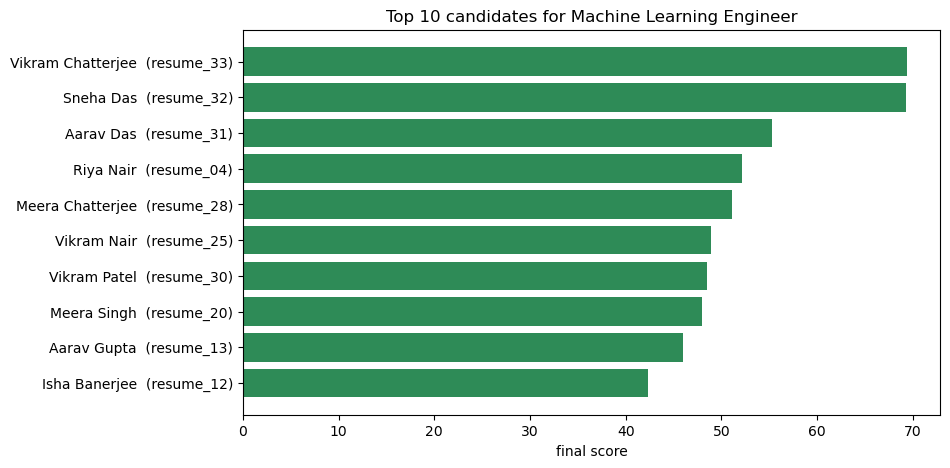

In [8]:
top = ranked.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top["name"] + "  (" + top["file"].str.replace(".txt", "", regex=False) + ")", top["final_score"], color="seagreen")
ax.set_xlabel("final score")
ax.set_title("Top 10 candidates for Machine Learning Engineer")
plt.savefig("outputs/01_top_candidates.png", dpi=120, bbox_inches="tight")
plt.show()

ranked.to_csv("outputs/ranked_candidates.csv")

## 7. Skill gap identification

In [9]:
gap = ranked.head(5)[["name", "final_score", "missing_required", "missing_preferred"]]
gap

,name,final_score,missing_required,missing_preferred
rank,,,,
1,Vikram Chatterjee,69.4,[numpy],"[aws, nlp, tensorflow]"
2,Sneha Das,69.3,[],"[aws, nlp]"
3,Aarav Das,55.3,"[deep learning, pandas, python, scikit-learn]","[aws, nlp]"
4,Riya Nair,52.2,"[scikit-learn, sql]","[aws, nlp]"
5,Meera Chatterjee,51.1,"[deep learning, git, numpy, sql]","[aws, nlp, pytorch]"


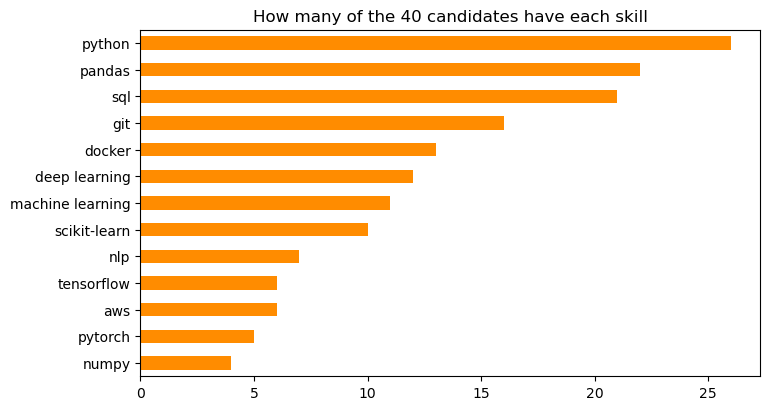

In [10]:
# which required skills are the hardest to find in the whole candidate pool?
pool_counts = {s: sum(s in sk for sk in df["skills"]) for s in sorted(required | preferred)}
s = pd.Series(pool_counts).sort_values()
s.plot(kind="barh", figsize=(8, 4.5), color="darkorange")
plt.title("How many of the 40 candidates have each skill")
plt.savefig("outputs/02_skill_availability.png", dpi=120, bbox_inches="tight")
plt.show()

## 8. Re-use for any other job role
The same function works for a new job description. Example: a Data Analyst role.

In [11]:
jd2 = '''Job Title: Data Analyst

Required Skills:
SQL, Excel, Python, pandas, statistics

Nice to have:
Power BI, Tableau, data visualization

Experience: 1+ years
'''
rank_candidates(df, jd2)[["name", "years", "required_match_%", "final_score", "missing_required"]].head(5)

,name,years,required_match_%,final_score,missing_required
rank,,,,,
1,Aarav Singh,1,100,83.0,[]
2,Rohan Singh,5,100,80.6,[]
3,Pooja Chatterjee,1,80,74.0,[sql]
4,Aarav Banerjee,5,80,73.1,[excel]
5,Tanvi Sharma,3,80,71.8,[excel]


## Conclusion
- The system ranks all 40 candidates in seconds and explains **why** each one scored the way it did (matched and missing skills).
- Skill match carries the most weight, TF-IDF similarity catches relevant wording beyond the skills list, and experience fit rewards seniority up to the required level.
- **Business use:** recruiters get a shortlist plus a skill-gap report instead of reading every resume.
- **Limits:** a screening tool should support, not replace, human review; scores depend on the skills dictionary and should be checked for bias before real use.
- **Next steps:** parse PDF/DOCX resumes, use spaCy entity matching, and add semantic embeddings.